# Задача 4.10 — Случайный отрезок в круге

---

## 1. Условие

В круге радиуса 1 наудачу выбирается отрезок. Найти вероятность того, что длина этого отрезка будет меньше радиуса круга.

**Ответ:** $1 - \dfrac{3}{4n^3}$ (в условии опечатка; имеется в виду $1 - \dfrac{3\sqrt{3}}{4\pi} \approx 0{,}5865$).

---

## 2. Теоретическая часть

Стандартная модель «случайной хорды» (Бертрана): концы отрезка выбираются независимо и равномерно в круге. Пусть $X, Y$ — две случайные точки в единичном круге. Тогда

$$
P(|X - Y| < 1) = 1 - P(|X - Y| \ge 1).
$$

Известный результат для двух случайных точек в круге радиуса $R$:

$$
P(|X - Y| \ge R) = \frac{3\sqrt{3}}{4\pi},
\qquad
P(|X - Y| < R) = 1 - \frac{3\sqrt{3}}{4\pi} \approx 0{,}5865.
$$

---

## 3. Решение

P(длина < R) = 1 - 3√3/(4π) ≈ 0.5865033284
Оценка: 0.586860


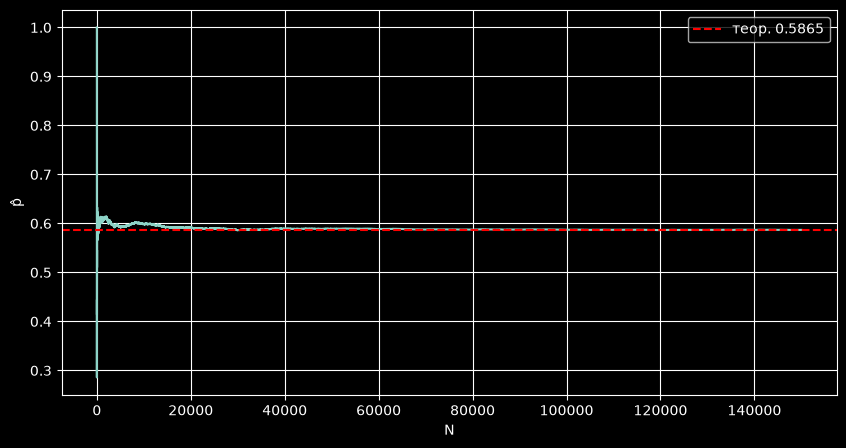

In [1]:
import numpy as np
import matplotlib.pyplot as plt

P_theor = 1 - 3*np.sqrt(3)/(4*np.pi)
print(f"P(длина < R) = 1 - 3√3/(4π) ≈ {P_theor:.10f}")

N = 150_000
rng = np.random.default_rng(seed=9)

def random_point_in_disk(n):
    r = np.sqrt(rng.uniform(0, 1, n))
    phi = rng.uniform(0, 2*np.pi, n)
    return r*np.cos(phi), r*np.sin(phi)

x1, y1 = random_point_in_disk(N)
x2, y2 = random_point_in_disk(N)
d = np.hypot(x1 - x2, y1 - y2)
hit = d < 1.0

print(f"Оценка: {hit.mean():.6f}")
freq = np.cumsum(hit) / np.arange(1, N+1)
plt.figure(figsize=(10, 5))
plt.plot(freq)
plt.axhline(P_theor, color="r", ls="--", label=f"теор. {P_theor:.4f}")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.show()